In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("../../datasets/heart_final_cleaned.csv")

df = df.dropna().reset_index(drop=True)

X = df.drop("target", axis=1).values.astype(float)
y = df["target"].values

print("Dataset Shape:", df.shape)
print("\nTarget Distribution:")
print(df["target"].value_counts())

Dataset Shape: (302, 14)

Target Distribution:
target
1    164
0    138
Name: count, dtype: int64


In [4]:
def k_fold_split(X, y, k=5, random_state=42):

    np.random.seed(random_state)

    indices = np.arange(len(X))
    np.random.shuffle(indices)

    folds = np.array_split(indices, k)

    for i in range(k):

        test_indices = folds[i]

        train_indices = np.concatenate([
            folds[j] for j in range(k) if j != i
        ])

        yield (
            X[train_indices],
            X[test_indices],
            y[train_indices],
            y[test_indices]
        )


print("Total Folds: 5")

Total Folds: 5


In [5]:
def gini_impurity(y):

    _, counts = np.unique(y, return_counts=True)

    probabilities = counts / len(y)

    return 1 - np.sum(probabilities ** 2)

In [6]:
def build_tree(X, y, depth=0, max_depth=6):

    classes, counts = np.unique(y, return_counts=True)
    prediction = classes[np.argmax(counts)]

    if len(classes) == 1 or depth >= max_depth or len(y) < 4:
        return prediction

    best_gain = 0
    best_feature = None
    best_threshold = None

    for feature in range(X.shape[1]):

        values = np.unique(X[:, feature])

        for threshold in (values[:-1] + values[1:]) / 2:

            left = X[:, feature] <= threshold
            right = ~left

            if not left.any() or not right.any():
                continue

            weighted_gini = (
                left.sum() * gini_impurity(y[left]) +
                right.sum() * gini_impurity(y[right])
            ) / len(y)

            gain = gini_impurity(y) - weighted_gini

            if gain > best_gain:
                best_gain = gain
                best_feature = feature
                best_threshold = threshold

    if best_feature is None:
        return prediction

    left = X[:, best_feature] <= best_threshold
    right = ~left

    return {
        "feature": best_feature,
        "threshold": best_threshold,
        "left": build_tree(X[left], y[left], depth + 1, max_depth),
        "right": build_tree(X[right], y[right], depth + 1, max_depth)
    }

In [7]:
def predict_tree(tree, row):

    while isinstance(tree, dict):

        if row[tree["feature"]] <= tree["threshold"]:
            tree = tree["left"]
        else:
            tree = tree["right"]

    return tree

In [8]:
def calculate_accuracy(y_actual, y_predicted):

    correct = 0

    for actual, predicted in zip(y_actual, y_predicted):

        if actual == predicted:
            correct += 1

    return (correct / len(y_actual)) * 100

In [9]:
k = 5
fold_accuracies = []

for fold_number, (X_train, X_test, y_train, y_test) in enumerate(
    k_fold_split(X, y, k), start=1
):

    tree = build_tree(X_train, y_train)

    y_pred = np.array([
        predict_tree(tree, row) for row in X_test
    ])

    accuracy = calculate_accuracy(y_test, y_pred)

    fold_accuracies.append(accuracy)

    print(f"Fold {fold_number} Accuracy: {accuracy:.2f}%")

Fold 1 Accuracy: 72.13%
Fold 2 Accuracy: 81.97%
Fold 3 Accuracy: 76.67%
Fold 4 Accuracy: 73.33%
Fold 5 Accuracy: 78.33%


In [10]:
average_accuracy = np.mean(fold_accuracies)

print("Individual Fold Accuracies:", fold_accuracies)
print("Average Accuracy:", round(average_accuracy, 2), "%")
print("Standard Deviation:", round(np.std(fold_accuracies), 2), "%")

Individual Fold Accuracies: [72.1311475409836, 81.9672131147541, 76.66666666666667, 73.33333333333333, 78.33333333333333]
Average Accuracy: 76.49 %
Standard Deviation: 3.53 %


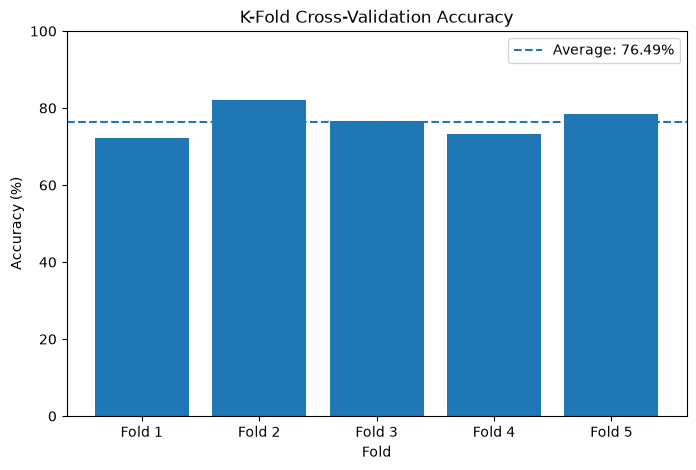

In [11]:
plt.figure(figsize=(8, 5))

plt.bar(
    [f"Fold {i+1}" for i in range(k)],
    fold_accuracies
)

plt.axhline(
    average_accuracy,
    linestyle="--",
    label=f"Average: {average_accuracy:.2f}%"
)

plt.title("K-Fold Cross-Validation Accuracy")
plt.xlabel("Fold")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)
plt.legend()
plt.show()

## Conclusion

In this task, K-Fold Cross-Validation was implemented manually using
a Decision Tree classifier.

The dataset was divided into five folds. In each iteration, four folds
were used for training and one fold was used for testing.

The accuracy of each fold was calculated manually, and the average
accuracy was used to evaluate the model's performance.

This technique helps evaluate model performance across multiple
data splits instead of depending on a single train-test split.